# Codveda Data Analytics Internship - Level 2 (Intermediate)
**Task 1:** Regression Analysis  **Task 2:** Clustering Analysis (K-Means)

Datasets: scikit-learn's built-in Diabetes (regression) and Wine (clustering) datasets.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_diabetes, load_wine
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error, silhouette_score
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA

sns.set_theme(style="whitegrid")
os.makedirs("plots", exist_ok=True)

## Task 1: Regression Analysis
Predict disease progression (`target`) one year after baseline.
First a simple linear regression (one predictor, BMI), then a multiple regression for comparison.

In [2]:
data = load_diabetes(as_frame=True)
df = data.frame
print(df.shape)
print(df.describe().round(3))

(442, 11)
           age      sex      bmi       bp  ...       s4       s5       s6   target
count  442.000  442.000  442.000  442.000  ...  442.000  442.000  442.000  442.000
mean    -0.000    0.000   -0.000   -0.000  ...   -0.000    0.000    0.000  152.133
std      0.048    0.048    0.048    0.048  ...    0.048    0.048    0.048   77.093
min     -0.107   -0.045   -0.090   -0.112  ...   -0.076   -0.126   -0.138   25.000
25%     -0.037   -0.045   -0.034   -0.037  ...   -0.039   -0.033   -0.033   87.000
50%      0.005   -0.045   -0.007   -0.006  ...   -0.003   -0.002   -0.001  140.500
75%      0.038    0.051    0.031    0.036  ...    0.034    0.032    0.028  211.500
max      0.111    0.051    0.171    0.132  ...    0.185    0.134    0.136  346.000

[8 rows x 11 columns]


### Split, fit, evaluate (simple regression: bmi -> target)

In [3]:
X = df[["bmi"]]
y = df["target"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

model = LinearRegression().fit(X_train, y_train)
pred = model.predict(X_test)

r2 = r2_score(y_test, pred)
mse = mean_squared_error(y_test, pred)
print(f"Intercept: {model.intercept_:.2f}")
print(f"Coefficient (bmi): {model.coef_[0]:.2f}")
print(f"R-squared: {r2:.3f}")
print(f"MSE: {mse:.2f}   RMSE: {np.sqrt(mse):.2f}")

Intercept: 152.00
Coefficient (bmi): 998.58
R-squared: 0.233
MSE: 4061.83   RMSE: 63.73


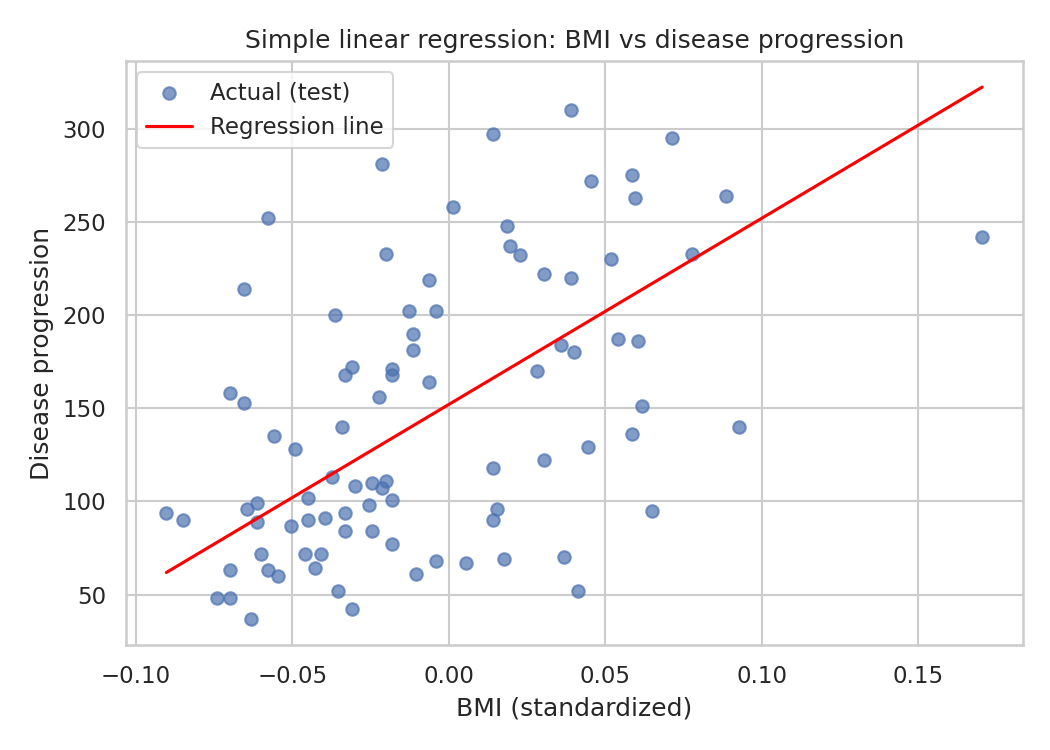

In [4]:
plt.figure(figsize=(7, 5))
plt.scatter(X_test, y_test, alpha=0.7, label="Actual (test)")
xs = np.linspace(X["bmi"].min(), X["bmi"].max(), 100).reshape(-1, 1)
plt.plot(xs, model.predict(pd.DataFrame(xs, columns=["bmi"])), color="red", label="Regression line")
plt.xlabel("BMI (standardized)"); plt.ylabel("Disease progression")
plt.title("Simple linear regression: BMI vs disease progression")
plt.legend(); plt.tight_layout(); plt.savefig("plots/regression_simple.png", dpi=150); plt.close()

### Multiple regression (all features) for comparison

Multiple regression  R2: 0.453   MSE: 2900.19
s1    -931.5
sex   -242.0
age     37.9
s6      48.7
s3     163.4
s4     275.3
bp     347.7
s2     518.1
bmi    542.4
s5     736.2
dtype: float64


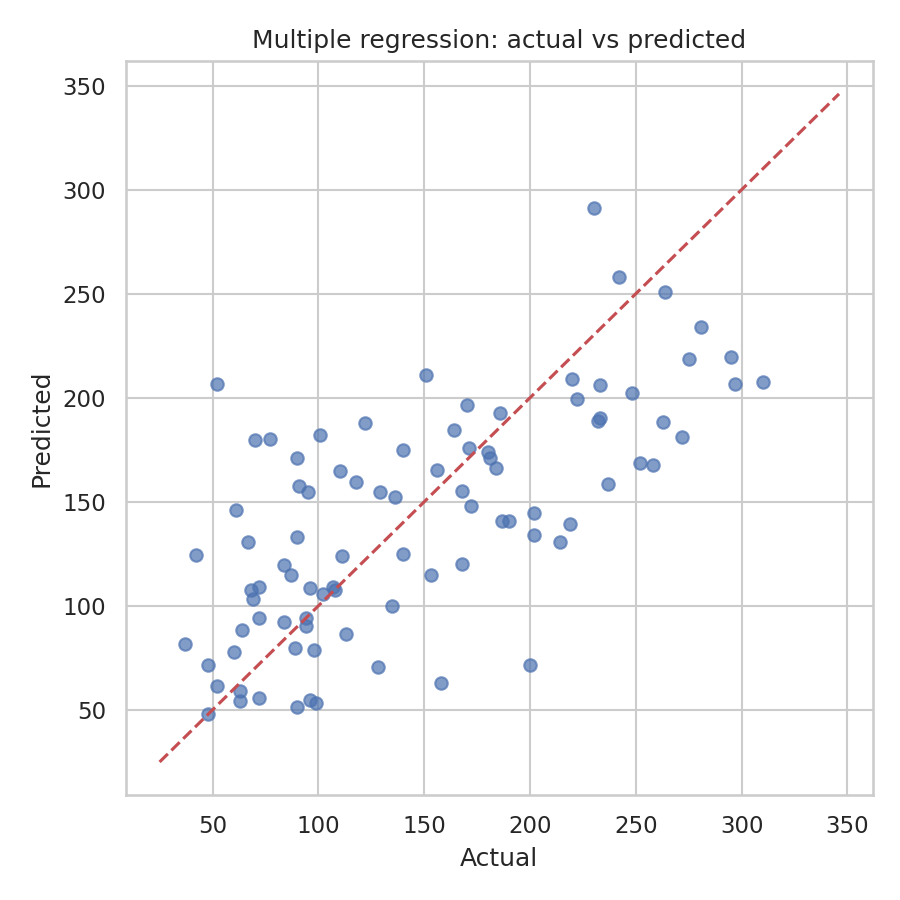

In [5]:
Xa = df.drop(columns="target")
Xa_train, Xa_test, ya_train, ya_test = train_test_split(Xa, y, test_size=0.2, random_state=42)
multi = LinearRegression().fit(Xa_train, ya_train)
pa = multi.predict(Xa_test)
print(f"Multiple regression  R2: {r2_score(ya_test, pa):.3f}   MSE: {mean_squared_error(ya_test, pa):.2f}")
print(pd.Series(multi.coef_, index=Xa.columns).sort_values().round(1))

plt.figure(figsize=(6, 6))
plt.scatter(ya_test, pa, alpha=0.7)
lims = [y.min(), y.max()]
plt.plot(lims, lims, "r--")
plt.xlabel("Actual"); plt.ylabel("Predicted"); plt.title("Multiple regression: actual vs predicted")
plt.tight_layout(); plt.savefig("plots/regression_multiple.png", dpi=150); plt.close()

**Interpretation:** sklearn's diabetes features are pre-scaled, so the BMI coefficient (~999) is per
unit of that scaled feature, not per BMI point. Its sign is positive: higher BMI is associated with
higher disease progression. BMI alone gives R-squared = 0.23 (RMSE ~ 64); using all ten features
raises R-squared to 0.45 (MSE 2900 vs 4062), so BMI matters but the outcome depends on several
factors (s5, bmi, s2 and bp carry the largest positive coefficients).

## Task 2: Clustering Analysis (K-Means)

(178, 13)
    k  inertia  silhouette
0   2   1658.8       0.259
1   3   1277.9       0.285
2   4   1175.4       0.260
3   5   1109.5       0.202
4   6   1046.0       0.237
5   7    981.6       0.204
6   8    935.2       0.157
7   9    889.9       0.150
8  10    845.9       0.144


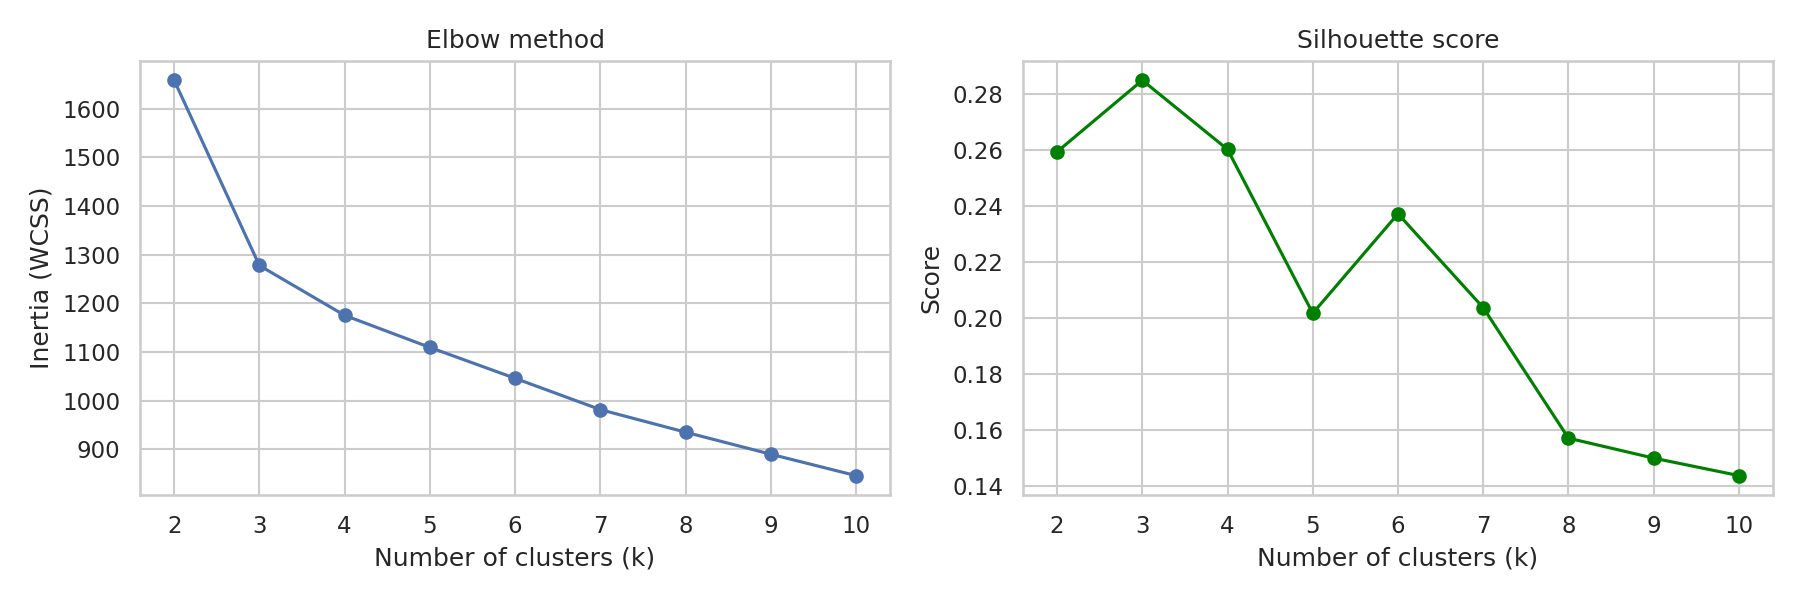

In [6]:
wine = load_wine(as_frame=True)
W = wine.frame.drop(columns="target")
print(W.shape)

# 1. standardize
Xs = StandardScaler().fit_transform(W)

# 2. elbow method + silhouette
ks = range(2, 11)
inertia, sil = [], []
for k in ks:
    km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(Xs)
    inertia.append(km.inertia_)
    sil.append(silhouette_score(Xs, km.labels_))

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(list(ks), inertia, "o-"); ax[0].set_title("Elbow method")
ax[0].set_xlabel("Number of clusters (k)"); ax[0].set_ylabel("Inertia (WCSS)")
ax[1].plot(list(ks), sil, "o-", color="green"); ax[1].set_title("Silhouette score")
ax[1].set_xlabel("Number of clusters (k)"); ax[1].set_ylabel("Score")
plt.tight_layout(); plt.savefig("plots/kmeans_elbow.png", dpi=150); plt.close()
print(pd.DataFrame({"k": list(ks), "inertia": np.round(inertia, 1), "silhouette": np.round(sil, 3)}))

Cluster sizes:
 cluster
0    65
1    51
2    62
Name: count, dtype: int64

Cluster profiles (feature means):
 cluster                            0       1        2
alcohol                        12.25   13.13    13.68
malic_acid                      1.90    3.31     2.00
ash                             2.23    2.42     2.47
alcalinity_of_ash              20.06   21.24    17.46
magnesium                      92.74   98.67   107.97
total_phenols                   2.25    1.68     2.85
flavanoids                      2.05    0.82     3.00
nonflavanoid_phenols            0.36    0.45     0.29
proanthocyanins                 1.62    1.15     1.92
color_intensity                 2.97    7.23     5.45
hue                             1.06    0.69     1.07
od280/od315_of_diluted_wines    2.80    1.70     3.16
proline                       510.17  619.06  1100.23

Silhouette at k=3: 0.285


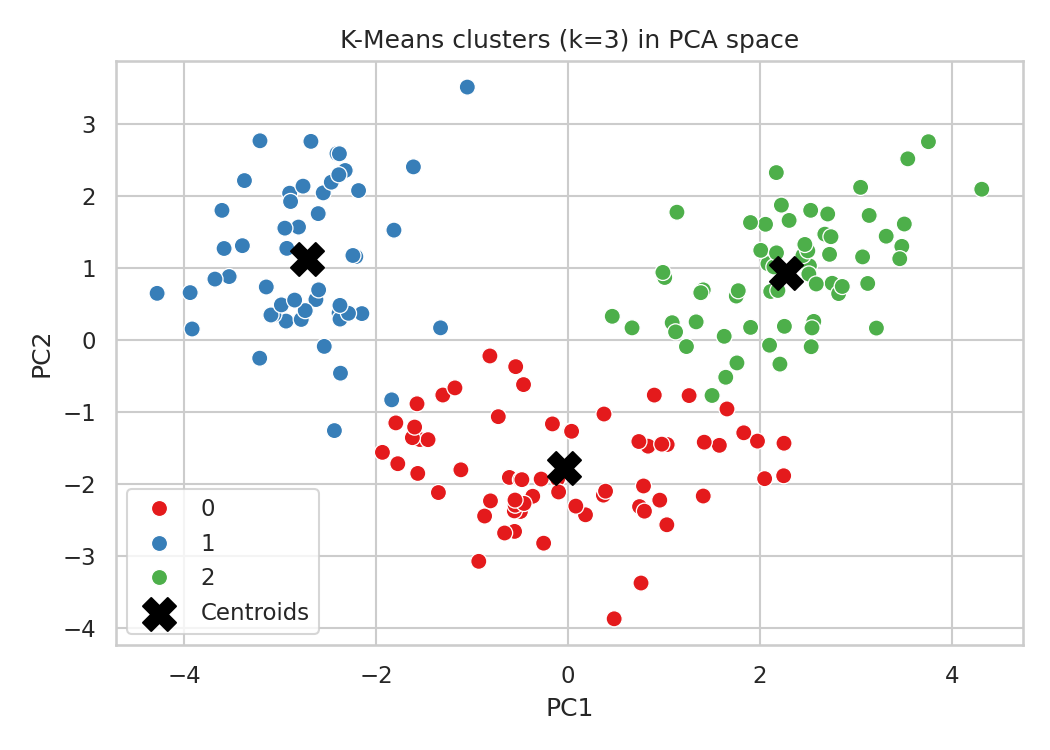

In [7]:
K = 3  # silhouette peaks at k=3 and the elbow flattens after it (also matches the 3 known wine cultivars)
km = KMeans(n_clusters=K, n_init=10, random_state=42).fit(Xs)
W["cluster"] = km.labels_

# 3. 2D visualization via PCA
pcs = PCA(n_components=2).fit_transform(Xs)
plt.figure(figsize=(7, 5))
sns.scatterplot(x=pcs[:, 0], y=pcs[:, 1], hue=W["cluster"], palette="Set1", s=60)
centers = PCA(n_components=2).fit(Xs).transform(km.cluster_centers_)
plt.scatter(centers[:, 0], centers[:, 1], marker="X", s=250, c="black", label="Centroids")
plt.title(f"K-Means clusters (k={K}) in PCA space"); plt.xlabel("PC1"); plt.ylabel("PC2")
plt.legend(); plt.tight_layout(); plt.savefig("plots/kmeans_clusters.png", dpi=150); plt.close()

print("Cluster sizes:\n", W["cluster"].value_counts().sort_index())
print("\nCluster profiles (feature means):\n", W.groupby("cluster").mean().round(2).T)
print("\nSilhouette at k=3:", round(silhouette_score(Xs, km.labels_), 3))